# 현실의 데이터 11: 서식 문서 이해

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SuminHan/book-ml/blob/main/notebooks/datashop/11_form_understanding.ipynb)

**분야**: 전문 서비스 &nbsp;|&nbsp; **이 분야에서 먼저 보는 문제**: 감사 자동화 · 문서지능 처리 · 리스크 · 내부통제

> 스캔한 서식 199장, 글 덩어리 9천여 개. 어느 것이 '질문' 이고 어느 것이 '답' 일까?

**데이터**: FUNSD (약 17MB). Jaume, Ekenel & Thiran (2019), Form Understanding in Noisy Scanned Documents. 스캔 서식 199장 (학습 149 · 시험 50), 글 덩어리마다 header · question · answer · other 표시.

인턴 · 산학협력 과제에서 처음 받게 될 데이터와 닮은 공개 데이터다. 데이터를 열어 보고, 아래 예시처럼 문제 하나를 정해 기준선과 비교한 뒤, 맨 끝의 **나의 다섯 칸** 을 채운다 (1주 2차시 '문제 정형화와 평가지표').

| 칸 | 이 노트북의 예시 |
|---|---|
| ① 한 행 | 서식 속 글 덩어리 하나 (상자 + 글자) |
| ② 입력 X | 위치 · 크기 · 글자 (콜론으로 끝나나, 숫자인가 …) |
| ③ 출력 y | header / question / answer / other |
| ④ 평가지표 | 정확도 + 종류별 재현율 |
| ⑤ 기준선 | 가장 흔한 종류 |

**논문 · 출처** (직접 열어 보자: 이 데이터를 누가, 왜, 어떻게 만들었나):
- [Jaume, Ekenel & Thiran (2019) FUNSD: A Dataset for Form Understanding in Noisy Scanned Documents](https://arxiv.org/abs/1905.13538)

In [1]:
import io, os, zipfile, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def download(url, path):
    """Download url to path once (skip if it already exists)"""
    os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
    if not os.path.exists(path):
        req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0 (ML course data shop)"})
        with urllib.request.urlopen(req, timeout=600) as r, open(path, "wb") as f:
            f.write(r.read())
    return path

## 입장: 데이터 받기

In [2]:
import json
URL = "https://guillaumejaume.github.io/FUNSD/dataset.zip"
zf = zipfile.ZipFile(download(URL, "data/funsd.zip"))
names = [n for n in zf.namelist() if n.endswith(".json") and "__MACOSX" not in n]
print(len(names), "annotated forms;", names[:2])

199 annotated forms; ['dataset/training_data/annotations/71206427.json', 'dataset/training_data/annotations/0001123541.json']


## 열어 보기

서식 한 장 = 사진 (png) + 글 덩어리 목록 (json). 한 장을 그려 보자. 색 = 종류.

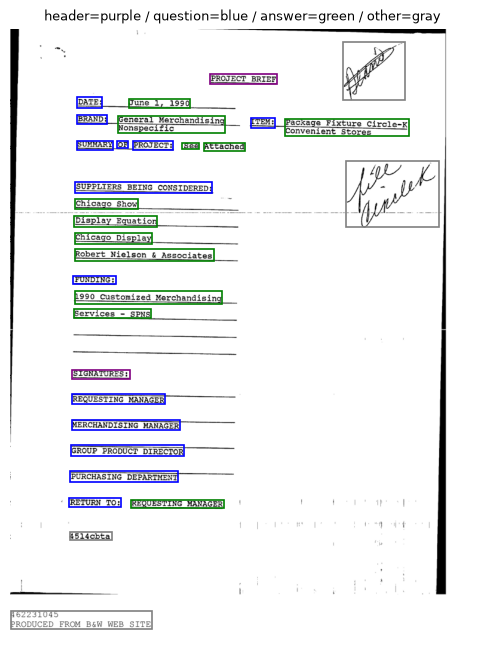

[('question', 'ITEM:'), ('question', 'DATE:'), ('question', 'BRAND:'), ('question', 'SUMMARY'), ('question', 'OF'), ('question', 'PROJECT:')]


In [3]:
from PIL import Image
COLORS = {"header": "purple", "question": "blue", "answer": "green", "other": "gray"}
name = names[0]
form = json.loads(zf.read(name))["form"]
img = Image.open(io.BytesIO(zf.read(name.replace("annotations", "images").replace(".json", ".png"))))
plt.figure(figsize=(6, 8)); plt.imshow(img, cmap="gray")
for block in form:
    x0, y0, x1, y1 = block["box"]
    plt.gca().add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, ec=COLORS[block["label"]], lw=1.2))
plt.axis("off"); plt.title(" / ".join(f"{k}={v}" for k, v in COLORS.items()), fontsize=9); plt.show()
print([(b["label"], b["text"]) for b in form[:6]])

## 문제 하나 골라 보기: 글 덩어리 → 종류

한 행 = 글 덩어리 하나. 사람이 서식을 볼 때 쓰는 단서를 숫자로 만든다: 위치, 크기, 글자 수, 콜론(`:`) 으로 끝나나, 숫자가 많은가, 대문자 비율. 학습 149장 · 시험 50장은 데이터가 정해 둔 대로 나눈다.

In [4]:
from sklearn.ensemble import RandomForestClassifier

def block_features(block, width, height):
    """Simple layout + text clues for one text block"""
    x0, y0, x1, y1 = block["box"]; t = block["text"]
    return dict(x=x0 / width, y=y0 / height, w=(x1 - x0) / width, h=(y1 - y0) / height, n_chars=len(t),
                ends_colon=float(t.strip().endswith(":")), digits=sum(c.isdigit() for c in t) / max(len(t), 1),
                upper=sum(c.isupper() for c in t) / max(sum(c.isalpha() for c in t), 1))

rows = []
for n in names:
    img = Image.open(io.BytesIO(zf.read(n.replace("annotations", "images").replace(".json", ".png"))))
    for b in json.loads(zf.read(n))["form"]:
        if b["text"].strip():
            rows.append({**block_features(b, *img.size), "label": b["label"], "split": "test" if "testing" in n else "train"})
blocks = pd.DataFrame(rows)
print(blocks.groupby("split")["label"].value_counts().unstack())

tr, te = blocks[blocks["split"] == "train"], blocks[blocks["split"] == "test"]
feats = [c for c in blocks.columns if c not in ("label", "split")]
most_common = tr["label"].value_counts().idxmax()
m = RandomForestClassifier(300, random_state=0).fit(tr[feats], tr["label"])
pred = m.predict(te[feats])
print(f"\nbaseline (always '{most_common}'): accuracy {np.mean(te['label'] == most_common):.1%}")
print(f"random forest on 8 clues       : accuracy {np.mean(te['label'] == pred):.1%}")
print("recall per label:", pd.Series(te["label"].values == pred).groupby(te["label"].values).mean().round(2).to_dict())

label  answer  header  other  question
split                                 
test      809     119    272      1070
train    2732     441    833      3253



baseline (always 'question'): accuracy 47.1%
random forest on 8 clues       : accuracy 75.2%
recall per label: {'answer': 0.72, 'header': 0.25, 'other': 0.49, 'question': 0.9}


## 다른 문제로 바꿔 보기

- **문서지능**: 종류를 맞힌 다음, 어느 '질문' 과 어느 '답' 이 짝인지 맞히는 문제 (FUNSD 의 `linking`) 로 넘어갈 수 있다. 출력이 '짝 목록' 이면 지표는?
- **감사 자동화**: 영수증 (SROIE), 계약서 (CUAD: 계약서 510건, 조항 41종) 처럼 서식이 정해진 문서라면 한 행 · 출력이 어떻게 바뀔까?
- **내부통제**: '틀린 서식' 을 찾는 문제라면 y 는 무엇이고, 그 정답은 누가 매기나?

### 나의 다섯 칸

아래 표를 직접 채워 보자. 위의 예시와 다르게 정해도 된다.

| 칸 | 내가 정한 것 |
|---|---|
| ① 한 행은 무엇? | |
| ② 입력 X (예측할 때 알 수 있는 것만) | |
| ③ 출력 y | |
| ④ 평가지표 | |
| ⑤ 기준선 | |